# Notebook 03 · Calibration, choix du modèle et règle de décision (validation seulement)

Ce notebook fixe tout ce qui transforme une probabilité en action, **en n'utilisant que l'entraînement et la validation** :
1. diagnostiquer la calibration des trois modèles (S8) et la corriger par Platt ;
2. choisir le modèle final selon une règle annoncée à l'avance ;
3. mesurer TP, FP, FN, TN, precision, recall et F1 selon le seuil (S7, S9) ;
4. tirer de la probabilité calibrée les actions acheter, neutre et vendre, par un calcul d'espérance de gain en euros ;
5. figer ces choix dans `runs/decision_finale.json`.

Le fichier est commité **avant** toute évaluation sur le test (notebook 03b), qui n'aura lieu qu'une fois. C'est la preuve que rien n'a été retouché après avoir vu le test.

**Règles de décision**
- **Calibration** : Platt appris sur les prédictions hors fold 2018-2021 (le « fold de calibration » de S8). La section 2 explique pourquoi pas sur la validation.
- **Choix du modèle** : la règle de baseline de S1, « a complex model is not successful unless it clearly beats both the no-skill floor and a simple baseline model ». On garde la régression logistique, sauf si un modèle plus complexe la bat à la fois en PR-AUC et en log-loss calibrée sur la validation.
- **Marge de décision** : fixée à l'avance à 0,5 %/mois (section 5), et non réglée sur la validation.
- **Couverture** : « toujours couvert », puisque le notebook 02 n'a trouvé aucun signal.

In [1]:
from pathlib import Path
import json
import subprocess
import warnings
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, log_loss

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "config.yaml"))
FIG, RUNS = ROOT / "figures", ROOT / "runs"
COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

table = pd.read_csv(ROOT / CFG["data"]["model_table"], parse_dates=["date"]).set_index("date")
train = table[table["bloc"] == "entraînement"]
valid = table[table["bloc"] == "validation"]

pred = pd.read_csv(RUNS / "predictions_02.csv", parse_dates=["date"])
nik = pred[pred["cible"] == "nikkei"]
MODELES = ["logit", "rf", "lgbm"]
NOMS = {"logit": "logistique", "rf": "Random Forest", "lgbm": "LightGBM", "moyenne": "moyenne des trois"}
P_va = nik[nik["bloc"] == "validation"].pivot(index="date", columns="modele", values="p")[MODELES]   # P(baisse)
P_oof = nik[nik["bloc"] == "hors fold"].pivot(index="date", columns="modele", values="p")[MODELES]
y_va = valid["y_baisse"].astype(int)
y_oof = train.loc[P_oof.index, "y_baisse"].astype(int)
print(f"validation : {len(y_va)} mois dont {y_va.sum()} baisses | hors fold : {len(y_oof)} mois dont {y_oof.sum()} baisses")

validation : 24 mois dont 10 baisses | hors fold : 48 mois dont 19 baisses


## 1. Les probabilités brutes sont-elles calibrées ? (S8)

Le **reliability diagram**, codé à la main comme dans S8 : on range les mois en 5 groupes de même taille selon la probabilité prédite, puis on compare dans chaque groupe la confiance moyenne conf(B<sub>m</sub>) à la fréquence observée acc(B<sub>m</sub>). Un modèle calibré suit la diagonale. On le trace sur les prédictions hors fold (48 mois, 2018-2021) et sur la validation (24 mois, 2022-2023).

$$\operatorname{conf}(B_m)=\frac{1}{|B_m|}\sum_{i\in B_m}\hat p_i,\qquad \operatorname{acc}(B_m)=\frac{1}{|B_m|}\sum_{i\in B_m}y_i,\qquad \operatorname{ECE}=\sum_{m=1}^{M}\frac{|B_m|}{n}\left|\operatorname{acc}(B_m)-\operatorname{conf}(B_m)\right|$$

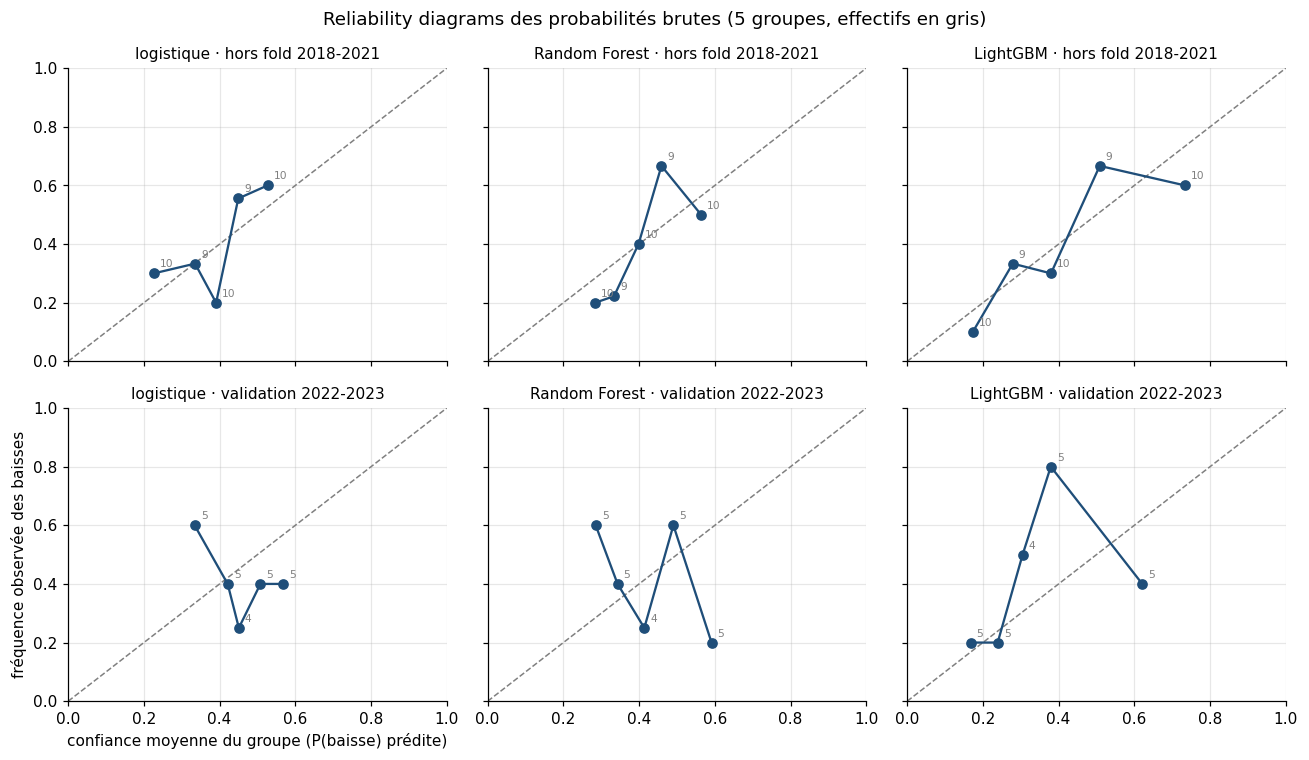

log-loss  Brier    ECE  PR-AUC  proba moyenne  \
hors fold  logistique        0.647  0.228  0.091   0.536          0.385   
           Random Forest     0.629  0.219  0.091   0.567          0.408   
           LightGBM          0.584  0.200  0.100   0.648          0.416   
validation logistique        0.701  0.253  0.151   0.489          0.456   
           Random Forest     0.742  0.273  0.209   0.440          0.425   
           LightGBM          0.710  0.257  0.181   0.524          0.344   

                          fréquence observée  
hors fold  logistique                  0.396  
           Random Forest               0.396  
           LightGBM                    0.396  
validation logistique                  0.417  
           Random Forest               0.417  
           LightGBM                    0.417

In [2]:
def fiabilite(y, p, M=5):
    groupes = pd.qcut(pd.Series(p).rank(method="first"), q=M, labels=False)
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p), "g": groupes.values})
    return d.groupby("g").agg(conf=("p", "mean"), acc=("y", "mean"), n=("y", "size"))

def ece(y, p, M=5):
    t = fiabilite(y, p, M)
    return float((t["n"] / t["n"].sum() * (t["acc"] - t["conf"]).abs()).sum())

def scores(y, p):
    return {"log-loss": log_loss(y, p, labels=[0, 1]), "Brier": brier_score_loss(y, p), "ECE": ece(y, p),
            "PR-AUC": average_precision_score(y, p), "proba moyenne": float(np.mean(p)), "fréquence observée": float(np.mean(y))}

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for j, m in enumerate(MODELES):
    for i, (nom_bloc, y, P) in enumerate([("hors fold 2018-2021", y_oof, P_oof), ("validation 2022-2023", y_va, P_va)]):
        ax = axes[i, j]
        t = fiabilite(y, P[m])
        ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
        ax.plot(t["conf"], t["acc"], marker="o", color="#1f4e79")
        for _, r in t.iterrows():
            ax.annotate(f"{int(r['n'])}", (r["conf"], r["acc"]), textcoords="offset points", xytext=(4, 4), fontsize=7, color="grey")
        ax.set_title(f"{NOMS[m]} · {nom_bloc}", fontsize=10)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[1, 0].set_xlabel("confiance moyenne du groupe (P(baisse) prédite)")
axes[1, 0].set_ylabel("fréquence observée des baisses")
fig.suptitle("Reliability diagrams des probabilités brutes (5 groupes, effectifs en gris)")
fig.tight_layout()
fig.savefig(FIG / "03_fiabilite_brute.png")
plt.show()

BRUT = pd.DataFrame({(bloc, NOMS[m]): scores(y, P[m]) for bloc, y, P in [("hors fold", y_oof, P_oof), ("validation", y_va, P_va)] for m in MODELES}).T
BRUT.round(3)

## 2. Recalibrer par Platt (S8)

Platt apprend, sur le fold de calibration, une sigmoïde du score brut *f* (le log-odds du modèle) :

$$g(f)=\frac{1}{1+e^{-(a\,f+c)}}$$

S8 note ses paramètres (*a*, *b*) ; ici (*a*, *c*), pour ne pas les confondre avec l'intercept *b* du modèle. La pente *a* dit comment le modèle se trompe : **a < 1** = probabilités trop extrêmes, donc modèle **sur-confiant** ; **a > 1** = probabilités trop timides, donc **sous-confiant**. Avec *a* > 0, Platt est croissante : elle ne change pas l'ordre des mois, donc pas la PR-AUC.

**Sur quelles données apprendre Platt ?** Un premier essai l'a ajustée sur la validation, comme le manuel le prévoyait. Résultat : une pente **négative** pour la logistique (a = −0,14) et pour le Random Forest (a = −0,62). La « calibration » apprenait à inverser ces modèles sur 24 mois. Ce n'est plus corriger un niveau ou une confiance (S8), c'est parier contre le modèle, appris en échantillon. Et la validation n'aurait plus pu juger honnêtement.

On apprend donc Platt sur les **prédictions hors fold 2018-2021** (48 mois). Chacune vient d'un modèle entraîné uniquement sur le passé, comme l'exige un fold de calibration. La validation redevient un juge honnête. La limite à signaler : les modèles hors fold sont entraînés sur moins de mois (95 à 131) que les modèles finaux (143).

In [3]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

PLATT = {}
for m in MODELES:
    cal = LogisticRegression(C=1e6, max_iter=1000).fit(logit(P_oof[m]).reshape(-1, 1), y_oof)
    PLATT[m] = {"a": float(cal.coef_[0, 0]), "c": float(cal.intercept_[0])}

def platt(p, m):
    return 1 / (1 + np.exp(-(PLATT[m]["a"] * logit(p) + PLATT[m]["c"])))

Pc_va = pd.DataFrame({m: platt(P_va[m], m) for m in MODELES}, index=P_va.index)
Pc_va["moyenne"] = Pc_va[MODELES].mean(axis=1)

lecture = {m: ("signal inversé (a < 0)" if PLATT[m]["a"] <= 0 else "sur-confiant (a < 1)" if PLATT[m]["a"] < 1 else "sous-confiant (a > 1)")
           for m in MODELES}
pd.DataFrame({NOMS[m]: {"a": PLATT[m]["a"], "c": PLATT[m]["c"], "lecture": lecture[m]} for m in MODELES}).T

,a,c,lecture
logistique,0.915448,0.010414,sur-confiant (a < 1)
Random Forest,1.535989,0.132422,sous-confiant (a > 1)
LightGBM,0.994804,-0.100988,sur-confiant (a < 1)


,log-loss,Brier,ECE,PR-AUC,proba moyenne,fréquence observée
logistique,0.699,0.253,0.150,0.489,0.462,0.417
Random Forest,0.796,0.296,0.240,0.440,0.421,0.417
LightGBM,0.717,0.261,0.183,0.524,0.325,0.417
moyenne des trois,0.713,0.258,0.107,0.451,0.403,0.417
constante (fréquence de l'entraînement),0.681,0.244,0.152,0.417,0.392,0.417


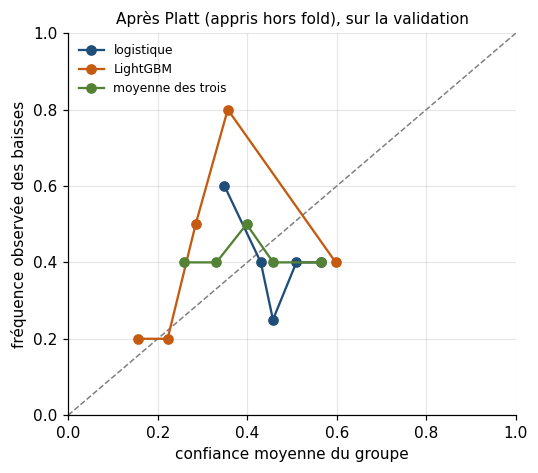

In [4]:
p_const = train["y_baisse"].mean()
APRES = pd.DataFrame({NOMS[m]: scores(y_va, Pc_va[m]) for m in Pc_va.columns}).T
APRES.loc["constante (fréquence de l'entraînement)"] = scores(y_va, np.full(len(y_va), p_const))
display(APRES.round(3))

fig, ax = plt.subplots(figsize=(5, 4.4))
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
for m, couleur in zip(["logit", "lgbm", "moyenne"], ["#1f4e79", "#c55a11", "#548235"]):
    t = fiabilite(y_va, Pc_va[m])
    ax.plot(t["conf"], t["acc"], marker="o", color=couleur, label=NOMS[m])
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("confiance moyenne du groupe"); ax.set_ylabel("fréquence observée des baisses")
ax.set_title("Après Platt (appris hors fold), sur la validation", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "03_fiabilite_platt.png")
plt.show()

## 3. Choix du modèle final : la règle de baseline de S1

On garde la logistique, sauf si un modèle plus complexe (Random Forest, LightGBM, ou la moyenne des trois) la bat **à la fois** en PR-AUC (classement, honnête car Platt ne le change pas) et en log-loss calibrée.

In [5]:
pr = {m: average_precision_score(y_va, Pc_va[m]) for m in Pc_va.columns}
ll = {m: log_loss(y_va, Pc_va[m], labels=[0, 1]) for m in Pc_va.columns}
regle = pd.DataFrame({"PR-AUC": pr, "log-loss calibrée": ll})
regle["bat la logistique sur les deux"] = [(pr[m] > pr["logit"]) and (ll[m] < ll["logit"]) if m != "logit" else np.nan for m in regle.index]
display(regle.rename(index=NOMS).round(4))

candidats = [m for m in ["rf", "lgbm", "moyenne"] if (pr[m] > pr["logit"]) and (ll[m] < ll["logit"])]
CHOIX = "logit" if not candidats else min(candidats, key=lambda m: ll[m])
print(f"modèle retenu : {NOMS[CHOIX]}" + ("" if candidats else " (aucun modèle plus complexe ne la bat clairement)"))
ll_const = log_loss(y_va, np.full(len(y_va), p_const), labels=[0, 1])
print(f"plancher sans compétence (S1) : log-loss {ll[CHOIX]:.3f} pour le modèle retenu contre {ll_const:.3f} pour la constante -> "
      + ("battu" if ll[CHOIX] < ll_const else "NON battu sur la validation"))

,PR-AUC,log-loss calibrée,bat la logistique sur les deux
logistique,0.4891,0.6993,NaN
Random Forest,0.4402,0.7964,False
LightGBM,0.5244,0.7172,False
moyenne des trois,0.4509,0.7131,False


modèle retenu : logistique (aucun modèle plus complexe ne la bat clairement)
plancher sans compétence (S1) : log-loss 0.699 pour le modèle retenu contre 0.681 pour la constante -> NON battu sur la validation


**Le modèle retenu ne bat pas le plancher sur la validation.** Aucun des trois ne le bat d'ailleurs. On ne le rejette pas pour autant sur 24 mois atypiques (section 3b). La décision, annoncée ici avant de voir le test : la logistique calibrée est évaluée une fois sur le test (notebook 03b). Si elle y perd aussi contre la constante, la recommandation finale sera la référence « toujours acheter, couvert ».

## 3b. Pourquoi le signal ne passe pas en 2022-2023 (S9 : de l'observation à l'hypothèse)

On compare, pour les variables les plus utilisées par la logistique, leur corrélation de rang avec le rendement du mois suivant sur l'entraînement et sur la validation.

In [6]:
mensuel = pd.read_csv(ROOT / CFG["data"]["monthly"], parse_dates=["date"]).set_index("date")
lignes = []
for c in ["news_attention_6m", "n225_mom_12m", "d_jgb10y_bp", "news_sent_w"]:
    a = train[c].corr(train["target_rn_next"], method="spearman")
    b = valid[c].corr(valid["target_rn_next"], method="spearman")
    lignes.append({"variable": c, "entraînement (2017-2021 pour les news)": a, "validation 2022-2023": b})
display(pd.DataFrame(lignes).set_index("variable").round(2))
print(f"articles BoJ par mois : {mensuel.loc['2017':'2021', 'news_boj_n_1m'].mean():.0f} en 2017-2021, "
      f"{mensuel.loc['2022':'2023', 'news_boj_n_1m'].mean():.0f} en 2022-2023")

,entraînement (2017-2021 pour les news),validation 2022-2023
variable,,
news_attention_6m,-0.38,0.29
n225_mom_12m,-0.11,-0.03
d_jgb10y_bp,-0.11,0.00
news_sent_w,0.03,-0.17


articles BoJ par mois : 55 en 2017-2021, 73 en 2022-2023


**Le signal principal s'est inversé.** Sur l'entraînement, un mois de news anormalement nombreuses annonçait plutôt une baisse (corrélation −0,38). En 2022-2023, il annonce plutôt une hausse (+0,29). Le volume d'articles sur la BoJ monte au même moment : ajustements du contrôle des taux longs fin 2022 et en 2023, changement de gouverneur en avril 2023.

**Hypothèse, à présenter comme telle.** Jusqu'en 2021, un pic de news traduisait surtout du stress. En 2022-2023, il traduit une normalisation de la politique monétaire qui accompagne un yen faible, favorable aux exportateurs. Le test (2024-2026) dira si ce changement dure. SHAP et les slices (notebook 04) permettront de le vérifier mois par mois.

## 4. TP, FP, FN, precision, recall et F1 selon le seuil (S7, S9)

Le tableau de la coding session 7, pour le modèle retenu : pour chaque seuil τ sur P(baisse) calibrée, on prédit « baisse » si P(baisse) ≥ τ. La classe positive est la baisse.

$$\text{Precision}=\frac{TP}{TP+FP},\qquad \text{Recall}=\frac{TP}{TP+FN},\qquad F_1=\frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

In [7]:
def tableau_seuils(y, p, seuils=np.round(np.arange(0.30, 0.71, 0.05), 2)):
    lignes = []
    for tau in seuils:
        yhat = (np.asarray(p) >= tau).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
        prec = tp / (tp + fp) if tp + fp else np.nan
        rec = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * prec * rec / (prec + rec) if tp else 0.0
        lignes.append({"seuil τ": tau, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                       "precision": prec, "recall": rec, "F1": f1, "accuracy": (tp + tn) / len(y)})
    return pd.DataFrame(lignes).set_index("seuil τ")

SEUILS = tableau_seuils(y_va, Pc_va[CHOIX])
print(f"{NOMS[CHOIX]}, validation ({y_va.sum()} baisses sur {len(y_va)} mois). Référence « toujours baisse » : F1 = {2 * y_va.mean() / (1 + y_va.mean()):.3f}")
SEUILS.round(3)

logistique, validation (10 baisses sur 24 mois). Référence « toujours baisse » : F1 = 0.588


,TP,FP,FN,TN,precision,recall,F1,accuracy
seuil τ,,,,,,,,
0.30,10,14,0,0,0.417,1.0,0.588,0.417
0.35,9,13,1,1,0.409,0.9,0.563,0.417
0.40,8,12,2,2,0.400,0.8,0.533,0.417
0.45,5,8,5,6,0.385,0.5,0.435,0.458
0.50,4,4,6,10,0.500,0.4,0.444,0.583
0.55,2,2,8,12,0.500,0.2,0.286,0.583
0.60,0,0,10,14,NaN,0.0,0.000,0.583
0.65,0,0,10,14,NaN,0.0,0.000,0.583
0.70,0,0,10,14,NaN,0.0,0.000,0.583


**Mêmes métriques pour les trois modèles (exigence 4)**, au seuil 0,5 et au seuil qui maximise le F1 de chaque modèle sur la validation. Ce second seuil est choisi sur la validation elle-même : il est optimiste.

In [8]:
lignes = []
for m in MODELES + ["moyenne"]:
    t = tableau_seuils(y_va, Pc_va[m])
    for nom_seuil, tau in [("0,5", 0.5), ("max F1", t["F1"].idxmax())]:
        r = t.loc[tau]
        lignes.append({"modèle": NOMS[m], "seuil": f"{nom_seuil} (τ = {tau:.2f})", **r[["TP", "FP", "FN", "TN", "precision", "recall", "F1"]].to_dict()})
pd.DataFrame(lignes).set_index(["modèle", "seuil"]).round(3)

TP    FP   FN    TN  precision  recall  \
modèle            seuil                                                         
logistique        0,5 (τ = 0.50)      4.0   4.0  6.0  10.0      0.500     0.4   
                  max F1 (τ = 0.30)  10.0  14.0  0.0   0.0      0.417     1.0   
Random Forest     0,5 (τ = 0.50)      3.0   6.0  7.0   8.0      0.333     0.3   
                  max F1 (τ = 0.30)   6.0  10.0  4.0   4.0      0.375     0.6   
LightGBM          0,5 (τ = 0.50)      2.0   2.0  8.0  12.0      0.500     0.2   
                  max F1 (τ = 0.30)   6.0   4.0  4.0  10.0      0.600     0.6   
moyenne des trois 0,5 (τ = 0.50)      2.0   2.0  8.0  12.0      0.500     0.2   
                  max F1 (τ = 0.30)   8.0  11.0  2.0   3.0      0.421     0.8   

                                        F1  
modèle            seuil                     
logistique        0,5 (τ = 0.50)     0.444  
                  max F1 (τ = 0.30)  0.588  
Random Forest     0,5 (τ = 0.50)     0.316  
                  max F1 (τ = 0.30)  0.462  
LightGBM          0,5 (τ = 0.50)     0.286  
                  max F1 (τ = 0.30)  0.600  
moyenne des trois 0,5 (τ = 0.50)     0.286  
                  max F1 (τ = 0.30)  0.552

## 5. De la probabilité à l'action : l'espérance de gain en euros

Le F1 récompense le recall de la baisse, donc pousse à vendre souvent. Or sur un indice qui monte 61 % des mois, une fausse alerte coûte cher. Le cours (S9, corrigé du HW1) demande de choisir le seuil selon le coût des erreurs, pas à 0,5 par défaut. On le fait ici en euros.

**Coûts estimés sur l'entraînement.** Rendement moyen de chaque action, en excès du cash, selon que le Nikkei a monté ou baissé :
- acheter couvert : *B<sub>u</sub>* (mois de hausse) et *B<sub>d</sub>* (mois de baisse) ;
- vendre : *S<sub>u</sub>* et *S<sub>d</sub>* ;
- neutre : le cash du mois, *c<sub>t</sub>* = i<sup>EUR</sup><sub>t</sub>/12, connu en *t*.

**Espérance de gain** avec la probabilité calibrée de hausse *p<sub>t</sub>*, puis la règle avec une marge *m* (le gain espéré minimal pour quitter le cash) :

$$\mathbb{E}[\text{acheter}]-c_t=p_t B_u+(1-p_t)B_d,\qquad \mathbb{E}[\text{vendre}]-c_t=p_t S_u+(1-p_t)S_d$$

$$\text{action}_t=\begin{cases}\text{la meilleure des deux} & \text{si son gain espéré au-dessus du cash dépasse } m\\ \text{neutre} & \text{sinon}\end{cases}\qquad\Rightarrow\qquad \theta_a=\frac{m-B_d}{B_u-B_d},\quad \theta_v=\frac{S_d-m}{S_d-S_u}$$

On achète si *p<sub>t</sub>* ≥ θ<sub>a</sub>, on vend si *p<sub>t</sub>* ≤ θ<sub>v</sub>. Les deux seuils viennent de coûts mesurés sur l'entraînement. Il ne reste qu'**un seul paramètre**, la marge *m*, et il est **fixé à l'avance à 0,5 %/mois** : on ne quitte le cash que si le gain espéré le dépasse d'au moins 6 % par an environ. C'est une préférence d'investisseur (S1 : « que veut dire réussir ? »), pas un réglage. Sans marge, la règle n'a presque jamais de zone neutre, puisque le gain espéré d'une vente est à peu près l'opposé de celui d'un achat. Le tableau des marges ci-dessous n'est qu'une analyse de sensibilité : le régler sur une validation où le Nikkei monte presque sans arrêt donnerait toujours « acheter ».

*Hors cours.* L'espérance de gain est une formule de décision simple, pas une notion des séances. Elle applique l'idée de S9 (« quelle erreur coûte le plus ? ») et demande des probabilités calibrées : c'est la décision en aval de l'exigence 9.

In [9]:
cash_tr = train["eur_overnight"] / 100 / 12
achat_tr = train["target_reur_hedged_next"] - cash_tr
vente_tr = train["target_short_eur_next"] - cash_tr
hausse_tr = train["y_baisse"] == 0
COUTS = {"B_u": float(achat_tr[hausse_tr].mean()), "B_d": float(achat_tr[~hausse_tr].mean()),
         "S_u": float(vente_tr[hausse_tr].mean()), "S_d": float(vente_tr[~hausse_tr].mean())}
display(pd.Series(COUTS, name="rendement moyen en excès du cash (%/mois)").mul(100).round(2).to_frame())

def seuils_de(m, k=COUTS):
    return {"theta_a": (m - k["B_d"]) / (k["B_u"] - k["B_d"]), "theta_v": (k["S_d"] - m) / (k["S_d"] - k["S_u"])}

def actions(p_hausse, m, k=COUTS):
    gain_achat = p_hausse * k["B_u"] + (1 - p_hausse) * k["B_d"]
    gain_vente = p_hausse * k["S_u"] + (1 - p_hausse) * k["S_d"]
    meilleur = np.where(gain_achat >= gain_vente, "acheter", "vendre")
    return pd.Series(np.where(np.maximum(gain_achat, gain_vente) >= m, meilleur, "neutre"), index=p_hausse.index)

def rendements(act, bloc):
    cash = bloc["eur_overnight"] / 100 / 12
    return np.select([act == "acheter", act == "vendre"], [bloc["target_reur_hedged_next"], bloc["target_short_eur_next"]], cash)

def perf(r):
    w = np.cumprod(1 + np.asarray(r))
    return {"cumul": w[-1] - 1, "perte maximale": float(np.min(w / np.maximum.accumulate(w)) - 1)}

,rendement moyen en excès du cash (%/mois)
B_u,3.89
B_d,-4.18
S_u,-3.89
S_d,4.18


In [10]:
p_hausse_va = 1 - Pc_va[CHOIX]
lignes = []
for m in [0.0, 0.0025, 0.005, 0.0075, 0.01, 0.015]:
    act = actions(p_hausse_va, m)
    r = rendements(act, valid)
    s = seuils_de(m)
    lignes.append({"marge m (%/mois)": 100 * m, "θ_v": s["theta_v"], "θ_a": s["theta_a"],
                   "mois acheter": int((act == "acheter").sum()), "mois neutre": int((act == "neutre").sum()),
                   "mois vendre": int((act == "vendre").sum()), **perf(r)})
GRILLE = pd.DataFrame(lignes).set_index("marge m (%/mois)")

refs = {"toujours acheter, couvert": valid["target_reur_hedged_next"], "toujours acheter, non couvert": valid["target_reur_unhedged_next"],
        "toujours neutre (cash)": valid["eur_overnight"] / 100 / 12}
REFS_VA = pd.DataFrame({k: perf(v) for k, v in refs.items()}).T
display(GRILLE.round(3))
display(REFS_VA.round(3))

M_CHOISI = 0.005
print(f"marge retenue, fixée à l'avance : m = {100 * M_CHOISI:.2f} %/mois -> θ_v = {seuils_de(M_CHOISI)['theta_v']:.3f}, "
      f"θ_a = {seuils_de(M_CHOISI)['theta_a']:.3f}")

,θ_v,θ_a,mois acheter,mois neutre,mois vendre,cumul,perte maximale
marge m (%/mois),,,,,,,
0.00,0.518,0.518,14,0,10,-0.165,-0.195
0.25,0.487,0.549,12,4,8,-0.160,-0.219
0.50,0.456,0.580,6,14,4,-0.104,-0.157
0.75,0.425,0.611,4,18,2,-0.096,-0.101
1.00,0.394,0.642,3,21,0,-0.047,-0.106
1.50,0.332,0.704,0,24,0,0.034,-0.003


,cumul,perte maximale
"toujours acheter, couvert",0.378,-0.075
"toujours acheter, non couvert",0.081,-0.110
toujours neutre (cash),0.034,-0.003


marge retenue, fixée à l'avance : m = 0.50 %/mois -> θ_v = 0.456, θ_a = 0.580


## 6. Le tableau des actions sur la validation

Avec la marge retenue, chaque action est croisée avec ce qui s'est passé le mois suivant. La precision de « vendre » est la part de ventes suivies d'une baisse ; le recall des baisses évitées est la part des baisses passées en neutre ou en vente.

y_baisse,hausse réalisée,baisse réalisée
row_0,,
acheter,3,3
neutre,9,5
vendre,2,2


precision de « acheter » : 0.50 | precision de « vendre » : 0.50 | recall des baisses évitées : 0.70


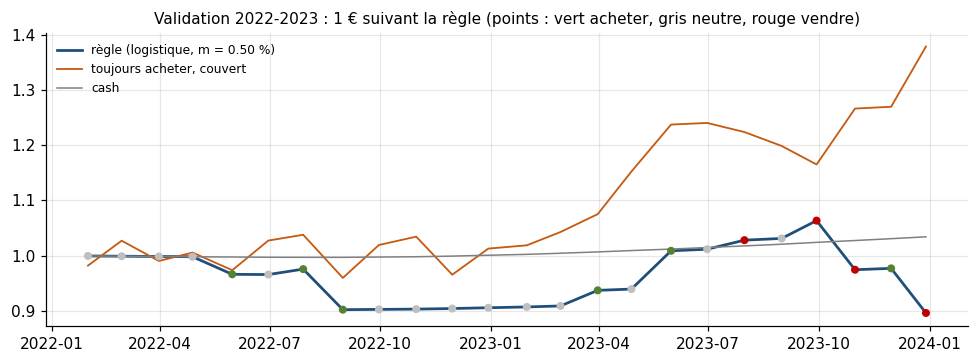

In [11]:
ACT_VA = actions(p_hausse_va, M_CHOISI)
croise = pd.crosstab(ACT_VA, y_va.map({0: "hausse réalisée", 1: "baisse réalisée"})).reindex(["acheter", "neutre", "vendre"], fill_value=0)
for col in ["hausse réalisée", "baisse réalisée"]:
    if col not in croise:
        croise[col] = 0
croise = croise[["hausse réalisée", "baisse réalisée"]]
display(croise)

n = croise
prec_achat = n.loc["acheter", "hausse réalisée"] / n.loc["acheter"].sum() if n.loc["acheter"].sum() else np.nan
prec_vente = n.loc["vendre", "baisse réalisée"] / n.loc["vendre"].sum() if n.loc["vendre"].sum() else np.nan
recall_evite = (n.loc["neutre", "baisse réalisée"] + n.loc["vendre", "baisse réalisée"]) / n["baisse réalisée"].sum()
print(f"precision de « acheter » : {prec_achat:.2f} | precision de « vendre » : {prec_vente:.2f} | recall des baisses évitées : {recall_evite:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.4))
w_strat = np.cumprod(1 + rendements(ACT_VA, valid))
ax.plot(valid.index, w_strat, color="#1f4e79", lw=1.8, label=f"règle ({NOMS[CHOIX]}, m = {100 * M_CHOISI:.2f} %)")
ax.plot(valid.index, np.cumprod(1 + valid["target_reur_hedged_next"]), color="#c55a11", lw=1.2, label="toujours acheter, couvert")
ax.plot(valid.index, np.cumprod(1 + valid["eur_overnight"] / 1200), color="grey", lw=1, label="cash")
couleur_action = {"acheter": "#548235", "neutre": "#bfbfbf", "vendre": "#c00000"}
ax.scatter(valid.index, w_strat, c=[couleur_action[a] for a in ACT_VA], s=18, zorder=3)
ax.set_title("Validation 2022-2023 : 1 € suivant la règle (points : vert acheter, gris neutre, rouge vendre)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "03_regle_validation.png")
plt.show()

## 7. Couverture : « toujours couvert »

Le notebook 02 n'a trouvé aucun signal pour la couverture : le meilleur réglage avait tous ses coefficients à zéro. La règle reste donc **h<sub>t</sub> = 1** quand on achète. Sur la validation, voici ce que ce choix a donné :

In [12]:
couv = pd.DataFrame({"couvert": perf(valid["target_reur_hedged_next"]), "non couvert": perf(valid["target_reur_unhedged_next"])}).T
couv["part des mois où c'était le meilleur choix"] = [1 - valid["y_non_couvert"].mean(), valid["y_non_couvert"].mean()]
couv.round(3)

,cumul,perte maximale,part des mois où c'était le meilleur choix
couvert,0.378,-0.075,0.708
non couvert,0.081,-0.110,0.292


## 8. Figer les choix avant le test

Tout ce qu'il faut pour appliquer la règle à un nouveau mois est écrit dans `runs/decision_finale.json`. Ce fichier est commité avant que le notebook 03b ne calcule quoi que ce soit sur le test.

In [13]:
DECISION = {
    "date": datetime.now().strftime("%Y-%m-%d %H:%M"), "commit_du_code": COMMIT,
    "modele_nikkei": CHOIX, "fichiers_modeles": {m: f"runs/models/nikkei_{m}.joblib" for m in MODELES},
    "sortie_du_modele": "P(baisse) ; p_hausse = 1 - P(baisse) calibrée",
    "platt": PLATT, "couts_entrainement_exces_du_cash": COUTS,
    "platt_appris_sur": "prédictions hors fold 2018-2021 (TimeSeriesSplit du notebook 02)",
    "marge_m": M_CHOISI, "marge_fixee_a_l_avance": True, "seuils": seuils_de(M_CHOISI),
    "couverture": "toujours couvert (h = 1)",
    "regle_choix_modele": "S1 : la logistique sauf si un modèle plus complexe la bat en PR-AUC et en log-loss calibrée sur la validation",
    "verdict_validation": {"log_loss_modele": ll[CHOIX], "log_loss_constante": ll_const, "plancher_battu": bool(ll[CHOIX] < ll_const)},
    "engagement_avant_test": "évaluer une seule fois sur le test ; si le modèle y perd aussi contre la constante, recommander « toujours acheter, couvert »",
}
(RUNS / "decision_finale.json").write_text(json.dumps(DECISION, indent=2, ensure_ascii=False))
print(json.dumps(DECISION, indent=2, ensure_ascii=False))

{
  "date": "2026-11-11 18:08",
  "commit_du_code": "2aa4b40",
  "modele_nikkei": "logit",
  "fichiers_modeles": {
    "logit": "runs/models/nikkei_logit.joblib",
    "rf": "runs/models/nikkei_rf.joblib",
    "lgbm": "runs/models/nikkei_lgbm.joblib"
  },
  "sortie_du_modele": "P(baisse) ; p_hausse = 1 - P(baisse) calibrée",
  "platt": {
    "logit": {
      "a": 0.9154481615258249,
      "c": 0.01041380261161088
    },
    "rf": {
      "a": 1.5359887472351588,
      "c": 0.1324221642348835
    },
    "lgbm": {
      "a": 0.9948037455190625,
      "c": -0.10098822029913068
    }
  },
  "couts_entrainement_exces_du_cash": {
    "B_u": 0.038925706206896546,
    "B_d": -0.04178659265476191,
    "S_u": -0.038852560137931036,
    "S_d": 0.04182417268452381
  },
  "platt_appris_sur": "prédictions hors fold 2018-2021 (TimeSeriesSplit du notebook 02)",
  "marge_m": 0.005,
  "marge_fixee_a_l_avance": true,
  "seuils": {
    "theta_a": 0.5796711692595266,
    "theta_v": 0.4564410505512501
  },
 

## 9. Ce qu'on retient

- **Calibration (S8, exigence 9).** Platt, appris sur les prédictions hors fold 2018-2021, donne des pentes positives :
    - logistique : a = 0,92, légèrement sur-confiante ;
    - Random Forest : a = 1,54, sous-confiant (la moyenne des arbres rend ses probabilités trop timides) ;
    - LightGBM : a = 0,99, bien calibré hors fold.
- **Sur la validation, les probabilités restent mal calibrées.** La logistique annonce 46 % de baisses en moyenne pour 42 % observés (ECE 0,150), et son reliability diagram descend au lieu de suivre la diagonale. **On ne ferait pas confiance à ces probabilités telles quelles pour décider** : c'est la réponse à l'exigence 9 sur la validation, et le test la confirmera ou non.
- **Un premier essai écarté.** Platt appris sur la validation donnait des pentes négatives : il inversait le modèle en échantillon.
- **Choix du modèle (règle de S1) : la logistique.** Aucun modèle plus complexe ne la bat à la fois en PR-AUC et en log-loss calibrée. LightGBM classe mieux (PR-AUC 0,524 contre 0,489), mais ses probabilités sont pires (0,717 contre 0,699).
- **Le plancher n'est pas battu.** Sur la validation, la logistique (log-loss 0,699) perd contre la constante (0,681). Son meilleur F1 (0,588 à τ = 0,30) est celui de « toujours baisse » : aucun seuil ne la fait mieux détecter les baisses que la règle triviale.
- **La raison principale.** Le volume anormal d'articles change de signe (−0,38 sur l'entraînement, +0,29 sur la validation) au moment où la BoJ commence à normaliser sa politique.
- **La règle de décision** combine l'espérance de gain, les coûts mesurés sur l'entraînement et une marge de 0,5 %/mois fixée à l'avance : θ<sub>v</sub> = 0,456 et θ<sub>a</sub> = 0,580. Sur la validation, elle donne 6 achats, 14 mois neutres et 4 ventes. Elle évite 7 des 10 baisses (recall 0,70), mais rate la hausse de 2023 : −10,4 % contre +37,8 % pour « toujours acheter, couvert ».
- **Couverture : toujours couvert.** Sur la validation, couvrir était le meilleur choix 71 % des mois (+37,8 % contre +8,1 % sans couverture).

**Engagement avant le test.** `runs/decision_finale.json` fige le modèle, la calibration, les coûts, la marge et la couverture. Il est commité avant le notebook 03b, qui évalue une seule fois sur le test 2024-2026. Si le modèle y perd aussi contre la constante, la recommandation finale sera « toujours acheter, couvert ».
